# 04 — Comparison, calibration and ONNX export
**Goal:** compare all models, pick the winner, calibrate it, export it to ONNX (+ INT8), and package it in
`models/winner/` for the API phase.

**Runtime:** a **CPU runtime** is best (Runtime → Change runtime type → CPU), since it matches the 2-vCPU, no-GPU
deployment box. A GPU runtime also works, because all latency numbers here are measured on the CPU with 2 threads.

Amendments vs. the original plan (see `Resources/model_training_plan.md`, *Plan Review & Amendments*):
- The winner score uses **correctness only**. Latency isn't scored by the organizers, so it's a pass/fail gate.
- The winner is selected on **dev**, and validation is reported as the held-out result.
- A **calibration** step (temperature scaling, urgency/secondary thresholds, `needs_human_review` threshold)
  was added, because `confidence` is used for calibration and abstention scoring.
- The INT8 model is kept only if its dev macro-F1 drop is ≤ 1 pt. FP32 ONNX must match PyTorch.

**v1.1 amendments (2026-10-09), after the first export was reviewed:**
- **Selection gates:** the 100-ticket batch time is an OpenAPI *target*, and the guidelines say latency is not
  scored. In v1 it excluded `xlmr-base` (30.12 s vs 30 s, measured on PyTorch fp32 *before* INT8), although
  xlmr-base had the best scores (val selection score 0.865 vs 0.536). It is now reported, not used as a gate.
- **Calibration data:** v1 fitted temperature and thresholds on dev, where the models are ~99% accurate. That
  sharpened confidences (T = 0.405) and made val ECE worse (0.089 → 0.252). Validation is now split 50/50:
  `val_cal` fits the decode settings, and `val_test` is the untouched held-out set for every reported number.
- **INT8 check:** uses the worse of the dev and val macro-F1 drops (dev is near-saturated, so it hides losses).
- **v1.1b (after the second run):** the PyTorch-fp32 p95 gate also removed. The same xlmr-base checkpoint measured
  585 ms in run 1 and 1017 ms in run 2 (shared Colab CPU noise), so it excluded the best model again. Only the
  size gate remains; latency is measured on the exported INT8 ONNX artifact in 4.11 and reported.
- **Review threshold** now has a 20% review budget (run 2 flagged 98% of val_test tickets for review).
- **Runtime check:** 4.11 fails fast if `src/tfml` on Drive is outdated (run 2's packaged runtime batched tickets,
  so INT8 predictions agreed only 94% with the per-ticket evaluation).

## 4.1 Load all metrics

In [1]:
# --- Environment setup (Colab or local) -------------------------------------------------
import os, sys, json, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = Path("/content/drive/MyDrive/TensorForge/training")   # upload the `training/` folder here
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(ROOT / "requirements-colab.txt")], check=True)
else:
    ROOT = Path.cwd().resolve().parent                  # training/notebooks -> training/

sys.path.insert(0, str(ROOT / "src"))
from tfml.paths import Paths
P = Paths(ROOT)
print("ROOT:", P.root, "| raw data:", P.raw_data)

import numpy as np, pandas as pd, torch, matplotlib.pyplot as plt, gc
from tfml import data as D, engine as E, metrics as M, export as X
from tfml.modeling import load_checkpoint_dir
from tfml.rules import decode_arrays, to_records, check_consistency
splits = D.load_processed(P)
data_config = json.loads(P.data_config.read_text())
TRANSFORMERS = ["xlmr-base", "minilm", "me5-small"]
allm = {f.name.replace("_metrics.json", ""): json.loads(f.read_text()) for f in P.results.glob("*_metrics.json")}
print("found:", list(allm))

Mounted at /content/drive
ROOT: /content/drive/MyDrive/TensorForge/training | raw data: /content/drive/MyDrive/TensorForge/training/data
found: ['xlmr-base', 'minilm', 'me5-small', 'tfidf-lr']


## 4.2 Comparison table

In [2]:
def row(name, m, split):
    v = m[split]
    return {"model": name, "split": split, "category_acc": v["category_acc"], "category_macro_f1": v["category_macro_f1"],
            "secondary_f1": v["secondary_f1"], "secondary_acc": v["secondary_acc"], "urgency_f1": v["urgency_f1"],
            "exact_match": v["exact_match"], "ece": v["ece"], "selection_score": M.selection_score(v),
            "size_mb": m.get("checkpoint_mb")}
comp = pd.DataFrame([row(n, m, s) for n, m in allm.items() for s in ("dev", "val")]).set_index(["model", "split"])
comp.round(4)

category_acc  category_macro_f1  secondary_f1  secondary_acc  \
model     split                                                                 
xlmr-base dev          0.9975             0.9960        0.9836         0.9975   
          val          0.8088             0.8136        0.8904         0.9800   
minilm    dev          0.8075             0.6286        0.1212         0.9275   
          val          0.5512             0.4225        0.2979         0.9175   
me5-small dev          0.9925             0.9889        0.5116         0.9500   
          val          0.7062             0.7294        0.4576         0.9238   
tfidf-lr  dev          0.9875             0.9842        0.9310         0.9900   
          val          0.6025             0.6253        0.6207         0.9450   

                 urgency_f1  exact_match     ece  selection_score    size_mb  
model     split                                                               
xlmr-base dev        0.9890       0.9950  0.0092           0.9912  1058.5404  
          val        0.9434       0.7938  0.1264           0.8652  1058.5404  
minilm    dev        0.0000       0.6800  0.2962           0.3446   448.3539  
          val        0.0000       0.4675  0.1140           0.2857   448.3539  
me5-small dev        0.3390       0.8500  0.2526           0.7071   448.3539  
          val        0.2292       0.5925  0.0586           0.5364   448.3539  
tfidf-lr  dev        0.9890       0.9775  0.0878           0.9721     5.3873  
          val        0.8742       0.5675  0.1745           0.6864     5.3873

## 4.3 Per-language breakdown (val, category accuracy)

          xlmr-base  minilm  me5-small  tfidf-lr
language                                        
en           0.8357  0.4893     0.8071    0.5036
singlish     0.6750  0.6150     0.6150    0.8500
si           0.8562  0.5312     0.5562    0.4812
ta           0.9167  0.6083     0.8333    0.6000
mixed        0.8500  0.6000     0.7000    0.4500
tanglish     0.7000  0.5500     0.6500    0.6500


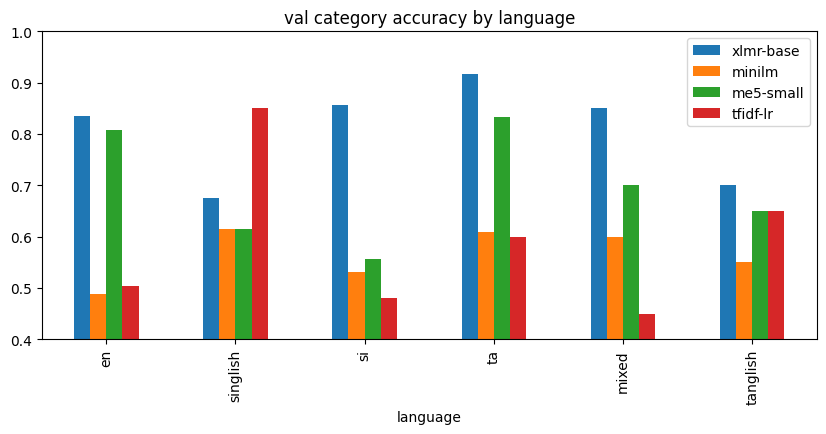

In [3]:
lang_tab = pd.DataFrame({n: pd.DataFrame(m["val_per_language"]).set_index("language")["category_acc"] for n, m in allm.items()})
print(lang_tab.round(4).to_string())
lang_tab.plot.bar(figsize=(10, 4), title="val category accuracy by language"); plt.ylim(lang_tab.min().min() - 0.05, 1.0)
plt.savefig(P.figures / "4_3_per_language.png", dpi=120, bbox_inches="tight"); plt.show()

## 4.4 CPU latency benchmark (PyTorch fp32, 2 threads ≈ 2 vCPU)
100 single-ticket predictions (tokenize + forward) → p50/p95/p99, plus one 100-ticket batch.

In [4]:
latency = {}
for key in TRANSFORMERS:
    ck = P.checkpoints / key / "best"
    if not (ck / "model.pt").exists():
        print("skip (not trained):", key); continue
    model, tok, meta = load_checkpoint_dir(ck, "cpu")
    latency[key] = E.benchmark_torch_cpu(model, tok, splits["val"], meta["max_length"], n_threads=2)
    print(key, {k: round(v, 1) for k, v in latency[key].items()})
    del model; gc.collect()
if "tfidf-lr" in allm:
    latency["tfidf-lr"] = allm["tfidf-lr"].get("latency_cpu", {})
lat = pd.DataFrame(latency).T
lat.round(1)

xlmr-base {'p50_ms': 286.0, 'p95_ms': 703.6, 'p99_ms': 1080.8, 'mean_ms': 344.0, 'batch100_s': 49.0}
minilm {'p50_ms': 80.2, 'p95_ms': 142.9, 'p99_ms': 163.2, 'mean_ms': 85.8, 'batch100_s': 13.5}
me5-small {'p50_ms': 75.8, 'p95_ms': 135.1, 'p99_ms': 163.1, 'mean_ms': 83.0, 'batch100_s': 13.1}


,p50_ms,p95_ms,p99_ms,mean_ms,batch100_s
xlmr-base,286.0,703.6,1080.8,344.0,49.0
minilm,80.2,142.9,163.2,85.8,13.5
me5-small,75.8,135.1,163.1,83.0,13.1
tfidf-lr,4.2,5.1,6.0,4.3,NaN


## 4.5 Winner selection
**Gate (pass/fail):** checkpoint < 2 GB (must fit the 4 GB box).
**Latency is reported, not gated (v1.1b):** latency is not scored (guidelines §3), the OpenAPI numbers are targets,
and the PyTorch-fp32 timings below come from a shared Colab CPU and vary run to run (xlmr-base p95: 585 ms in run 1,
1017 ms in run 2, same checkpoint). The deployed artifact is INT8 ONNX, so the real latency is measured on it in 4.11.

**Score (on dev):** `0.5·F1_category(macro) + 0.25·F1_secondary + 0.25·F1_urgency`

Only transformer models are eligible for ONNX export. The TF-IDF model is a reference point.
If it ties with the transformers, that's worth reporting: the data is synthetic and partly templated.

In [5]:
cands = []
for key in TRANSFORMERS:
    if key not in allm or key not in latency: continue
    m, l = allm[key], latency[key]
    # Hard gate: size only. Latency targets are informational (see the markdown above).
    gates = {"size_ok": m["checkpoint_mb"] < 2048}
    cands.append({"model": key, "dev_score": M.selection_score(m["dev"]), "val_score": M.selection_score(m["val"]),
                  "p95_ms": l["p95_ms"], "batch100_s": l["batch100_s"], "size_mb": m["checkpoint_mb"], **gates,
                  "p95_target_met": l["p95_ms"] < 1000, "batch_target_met": l["batch100_s"] < 30,
                  "eligible": all(gates.values())})
cand_df = pd.DataFrame(cands).set_index("model").sort_values("dev_score", ascending=False)
print(cand_df.round(4).to_string())

WINNER_OVERRIDE = None          # set e.g. "minilm" to force a choice
eligible = cand_df[cand_df.eligible]
assert len(eligible), "No model passes the deployment gates"
# Within 0.5 pt of the best dev score, prefer the faster model.
top = eligible.dev_score.max()
near = eligible[eligible.dev_score >= top - 0.005].sort_values("p95_ms")
WINNER = WINNER_OVERRIDE or near.index[0]
print("\nWINNER:", WINNER)
if not (cand_df.loc[WINNER, "p95_target_met"] and cand_df.loc[WINNER, "batch_target_met"]):
    print(f"note: PyTorch-fp32 p95 = {cand_df.loc[WINNER, 'p95_ms']:.0f} ms, 100-batch = "
          f"{cand_df.loc[WINNER, 'batch100_s']:.1f} s on Colab CPU; re-measured on the INT8 ONNX artifact in 4.11")

summary = comp.reset_index().pivot(index="model", columns="split").round(4)
summary.to_csv(P.results / "metrics.csv")
cand_df.join(lat, rsuffix="_lat").to_csv(P.results / "selection.csv")

           dev_score  val_score    p95_ms  batch100_s    size_mb  size_ok  p95_target_met  batch_target_met  eligible
model                                                                                                                
xlmr-base     0.9912     0.8652  703.6079     49.0316  1058.5404     True            True             False      True
me5-small     0.7071     0.5364  135.1194     13.1329   448.3539     True            True              True      True
minilm        0.3446     0.2857  142.8826     13.5254   448.3539     True            True              True      True

WINNER: xlmr-base
note: PyTorch-fp32 p95 = 704 ms, 100-batch = 49.0 s on Colab CPU; re-measured on the INT8 ONNX artifact in 4.11


## 4.6 ONNX export (FP32)

In [6]:
ck = P.checkpoints / WINNER / "best"
model, tok, meta = load_checkpoint_dir(ck, "cpu", attn_implementation="eager")  # eager attention traces cleanly
MAXLEN = meta["max_length"]
stage = P.models / "staging"; stage.mkdir(parents=True, exist_ok=True)
fp32_path = X.export_onnx(model, tok, stage / "model_fp32.onnx")
print(fp32_path, f"{E.dir_size_mb(fp32_path):.0f} MB")

/usr/local/lib/python3.13/dist-packages/transformers/masking_utils.py:214: TracerWarning: Converting a tensor to a Python boolean might cause the trace to be incorrect. We can't record the data flow of Python values, so this value will be treated as a constant in the future. This means that the trace might not generalize to other inputs!
  if (padding_length := kv_length + kv_offset - attention_mask.shape[-1]) > 0:
/usr/local/lib/python3.13/dist-packages/transformers/masking_utils.py:609: TracerWarning: torch.tensor results are registered as constants in the trace. You can safely ignore this warning if you use this function to create tensors out of constant variables that would be the same every time you call this function. In any other case, this might cause the trace to be incorrect.
  mask = torch.where(mask, torch.tensor(0.0, device=mask.device, dtype=dtype), min_dtype)
/usr/local/lib/python3.13/dist-packages/torch/onnx/_internal/torchscript_exporter/symbolic_opset11.py:954: UserWa

/content/drive/MyDrive/TensorForge/training/models/staging/model_fp32.onnx 1059 MB


## 4.7 ONNX validation: FP32 ONNX must reproduce PyTorch on the full validation set

In [7]:
val_df, dev_df = splits["val"], splits["dev"]
torch.set_num_threads(4)
pt_logits = E.predict_logits(model, E.make_loader(D.TicketDataset(tok, val_df, MAXLEN), 32, tok.pad_token_id, False), "cpu")
ox_logits = X.onnx_logits(fp32_path, tok, val_df, MAXLEN, n_threads=4)
for k in pt_logits:
    diff = np.abs(pt_logits[k] - ox_logits[k]).max()
    agree = (pt_logits[k].argmax(1) == ox_logits[k].argmax(1)).mean()
    print(f"{k:10s} max|Δlogit|={diff:.2e}  argmax agreement={agree:.4%}")
    assert diff < 1e-2 and agree == 1.0, f"ONNX mismatch on {k}"
print("FP32 ONNX matches PyTorch ✔")

category   max|Δlogit|=1.19e-04  argmax agreement=100.0000%
secondary  max|Δlogit|=3.72e-05  argmax agreement=100.0000%
urgency    max|Δlogit|=4.03e-05  argmax agreement=100.0000%
FP32 ONNX matches PyTorch ✔


## 4.8 INT8 dynamic quantization

In [8]:
int8_path = X.quantize_int8(fp32_path, stage / "model_int8.onnx")
print(f"fp32 {E.dir_size_mb(fp32_path):.0f} MB -> int8 {E.dir_size_mb(int8_path):.0f} MB")

art_logits, art_metrics = {}, {}
for name, path in [("fp32", fp32_path), ("int8", int8_path)]:
    for s, df in [("dev", dev_df), ("val", val_df)]:
        # batch_size=1: exactly how the packaged runtime runs (INT8 dynamic quantization is
        # batch-dependent), so thresholds/calibration are fitted on the logits the API will produce.
        lg = X.onnx_logits(path, tok, df, MAXLEN, n_threads=4, batch_size=1)
        art_logits[(name, s)] = lg
        art_metrics[(name, s)] = M.compute_metrics(df, decode_arrays(lg["category"], lg["secondary"], lg["urgency"]))
q = pd.DataFrame(art_metrics).T[["category_acc", "category_macro_f1", "secondary_f1", "urgency_f1", "exact_match"]]
print(q.round(4).to_string())

# v1.1: dev is near-saturated (~99%), so also check val and use the worse drop.
drops = {s: art_metrics[("fp32", s)]["category_macro_f1"] - art_metrics[("int8", s)]["category_macro_f1"]
         for s in ("dev", "val")}
drop = max(drops.values())
ARTIFACT = "int8" if drop <= 0.01 else "fp32"
print(f"macro-F1 drop from INT8: dev {drops['dev']:.4f}, val {drops['val']:.4f} -> using {ARTIFACT}")
art_path = int8_path if ARTIFACT == "int8" else fp32_path

fp32 1059 MB -> int8 266 MB
          category_acc  category_macro_f1  secondary_f1  urgency_f1  exact_match
fp32 dev        0.9975             0.9960        0.9836      0.9890       0.9950
     val        0.8088             0.8136        0.8904      0.9434       0.7938
int8 dev        0.9775             0.9695        0.9180      0.8941       0.9525
     val        0.7000             0.7110        0.6822      0.9054       0.6662
macro-F1 drop from INT8: dev 0.0265, val 0.1026 -> using fp32


## 4.9 Calibration and decision thresholds (fitted on `val_cal`, evaluated on `val_test`)
**Why not dev (v1.1):** dev comes from the training distribution and the winner is ~99% accurate there, so a
temperature fitted on dev *sharpens* confidences and dev-tuned thresholds don't transfer (v1: T = 0.405,
val ECE 0.089 → 0.252). Validation is split 50/50, stratified by category (seed 42):
- `val_cal` (400): fits everything below.
- `val_test` (400): never used for fitting. **Every number reported after this cell is on `val_test`.**

What is fitted:
- **Temperature scaling** on the category logits, so `confidence` reflects real accuracy (lower ECE).
- **Urgency threshold:** maximizes urgency F1 (10% positives, so 0.5 is rarely optimal).
- **Secondary threshold:** P(best non-primary label) ≥ t, maximizing secondary F1.
- **`needs_human_review`:** confidence below the smallest threshold at which auto-routed tickets reach
  ≥ 97% category accuracy, **with a 20% review budget** (v1.1b): if 97% needs more than 20% of tickets
  flagged, use the highest threshold that flags at most 20% (the least confident tickets).

The dev-fitted variant (v1 method) is fitted too and compared on `val_test`.

In [9]:
from sklearn.model_selection import train_test_split
from tfml.rules import softmax

def subset(lg, idx):
    # Slice every head's logits. Example: subset(vl, [0, 5]) -> {"category": (2, 11), "secondary": (2, 12), ...}
    return {k: v[idx] for k, v in lg.items()}

def fit_decode(lg, y, name):
    """Fit temperature + urgency/secondary/review thresholds on (logits, labels). Returns (DECODE, risk table)."""
    T = E.fit_temperature(lg["category"], y["category"])
    urg_t, urg_f = E.tune_threshold(softmax(lg["urgency"])[:, 1], y["urgency"] == 1)

    def sec_f1_at(t):
        dec = decode_arrays(lg["category"], lg["secondary"], lg["urgency"], {"temperature": T, "secondary_threshold": t})
        return M.secondary_scores(y["secondary"], dec["secondary"])["secondary_f1"]
    grid = np.round(np.arange(0.05, 0.951, 0.025), 3)
    sec_scores = [sec_f1_at(t) for t in grid]
    sec_t = float(grid[int(np.argmax(sec_scores))])
    argmax_f1 = sec_f1_at(None)
    if argmax_f1 >= max(sec_scores):
        sec_t = None   # plain argmax (incl. "none") is at least as good

    dec = decode_arrays(lg["category"], lg["secondary"], lg["urgency"], {"temperature": T})
    rc = E.risk_coverage(dec["confidence"], dec["category"] == y["category"])
    # Review rule: reach 97% auto-routed accuracy, but never flag more than 20% of tickets.
    REVIEW_TARGET_ACC, REVIEW_BUDGET = 0.97, 0.20
    ok = rc[(rc.auto_routed_acc >= REVIEW_TARGET_ACC) & (rc.review_rate <= REVIEW_BUDGET)]
    within = rc[rc.review_rate <= REVIEW_BUDGET]
    review_t = (float(ok.threshold.min()) if len(ok)
                else float(within.threshold.max()) if len(within) else float(rc.threshold.min()))
    print(f"[{name}] temperature={T:.3f} | urgency_threshold={urg_t} (F1 {urg_f:.4f}) | secondary_threshold={sec_t} "
          f"(F1 {max(max(sec_scores), argmax_f1):.4f} vs argmax {argmax_f1:.4f}) | review_threshold={review_t}")
    return {"temperature": T, "urgency_threshold": urg_t, "secondary_threshold": sec_t, "review_threshold": review_t}, rc

# 50/50 stratified split of validation: val_cal fits, val_test reports.
cal_idx, test_idx = train_test_split(np.arange(len(val_df)), test_size=0.5, random_state=42,
                                     stratify=val_df["category"])
cal_idx, test_idx = np.sort(cal_idx), np.sort(test_idx)
val_cal_df = val_df.iloc[cal_idx].reset_index(drop=True)
val_test_df = val_df.iloc[test_idx].reset_index(drop=True)
print(f"val_cal n={len(val_cal_df)} | val_test n={len(val_test_df)}")

dl, vl = art_logits[(ARTIFACT, "dev")], art_logits[(ARTIFACT, "val")]
vl_cal, vl_test = subset(vl, cal_idx), subset(vl, test_idx)

DECODE_DEV, _ = fit_decode(dl, D.encode_labels(dev_df), "dev (v1 method)")
DECODE, rc = fit_decode(vl_cal, D.encode_labels(val_cal_df), "val_cal (used)")
print(rc.round(4).to_string())

val_cal n=400 | val_test n=400
[dev (v1 method)] temperature=0.565 | urgency_threshold=0.15 (F1 0.9890) | secondary_threshold=None (F1 0.9836 vs argmax 0.9836) | review_threshold=0.3
[val_cal (used)] temperature=1.595 | urgency_threshold=0.425 (F1 0.9670) | secondary_threshold=0.4 (F1 0.8947 vs argmax 0.8800) | review_threshold=0.7
    threshold  coverage  auto_routed_acc  review_rate
0        0.30    0.9875           0.8228       0.0125
1        0.35    0.9825           0.8270       0.0175
2        0.40    0.9725           0.8355       0.0275
3        0.45    0.9575           0.8355       0.0425
4        0.50    0.9400           0.8404       0.0600
5        0.55    0.9200           0.8533       0.0800
6        0.60    0.8800           0.8722       0.1200
7        0.65    0.8475           0.8879       0.1525
8        0.70    0.8025           0.9065       0.1975
9        0.75    0.7550           0.9172       0.2450
10       0.80    0.6975           0.9211       0.3025
11       0.85    0

held-out val_test (n=400)
                      default (T=1, argmax)  fitted on dev (v1)  fitted on val_cal (used)
n                                  400.0000            400.0000                  400.0000
category_acc                         0.8025              0.8025                    0.8025
category_macro_f1                    0.8057              0.8057                    0.8057
category_weighted_f1                 0.8101              0.8101                    0.8101
secondary_acc                        0.9825              0.9825                    0.9825
secondary_precision                  1.0000              1.0000                    1.0000
secondary_recall                     0.8205              0.8205                    0.8205
secondary_f1                         0.9014              0.9014                    0.9014
urgency_acc                          0.9875              0.9875                    0.9900
urgency_precision                    0.9143              0.8718           

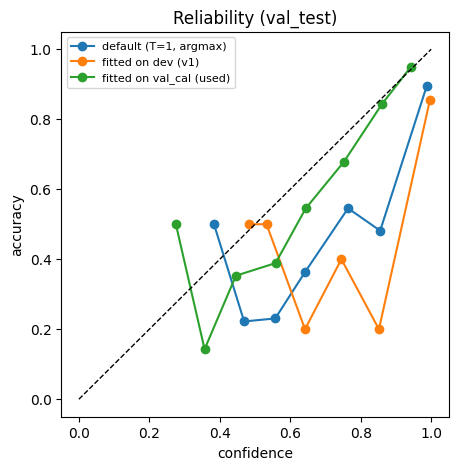

In [10]:
# Compare decode settings on the untouched val_test half.
yt = D.encode_labels(val_test_df)
variants = {"default (T=1, argmax)": {}, "fitted on dev (v1)": DECODE_DEV, "fitted on val_cal (used)": DECODE}
decs = {n: decode_arrays(vl_test["category"], vl_test["secondary"], vl_test["urgency"], cfg) for n, cfg in variants.items()}
m_by = {n: M.compute_metrics(val_test_df, d) for n, d in decs.items()}
print(f"held-out val_test (n={len(val_test_df)})")
print(pd.DataFrame(m_by).round(4).to_string())

dec_default, dec_tuned = decs["default (T=1, argmax)"], decs["fitted on val_cal (used)"]
m_default, m_tuned = m_by["default (T=1, argmax)"], m_by["fitted on val_cal (used)"]
print("val_test review rate:", round(dec_tuned["needs_human_review"].mean(), 4),
      "| auto-routed acc:", round((dec_tuned["category"] == yt["category"])[~dec_tuned["needs_human_review"]].mean(), 4))

# Full validation with the chosen settings (optimistic: includes val_cal). Used for the packaging parity check.
dec_tuned_full = decode_arrays(vl["category"], vl["secondary"], vl["urgency"], DECODE)
m_tuned_full = M.compute_metrics(val_df, dec_tuned_full)

# Reliability diagram (val_test)
def reliability(conf, correct, bins=10):
    b = np.minimum((conf * bins).astype(int), bins - 1)
    return pd.DataFrame({"b": b, "conf": conf, "acc": correct}).groupby("b").mean()
fig, ax = plt.subplots(figsize=(5, 5))
for name, d in decs.items():
    r = reliability(d["confidence"], d["category"] == yt["category"]); ax.plot(r.conf, r.acc, marker="o", label=name)
ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("confidence"); ax.set_ylabel("accuracy"); ax.legend(fontsize=8)
ax.set_title("Reliability (val_test)")
plt.savefig(P.figures / "4_9_reliability.png", dpi=120, bbox_inches="tight"); plt.show()

## 4.10 Package the winner → `models/winner/`

In [11]:
final_metrics = {
    "winner": WINNER, "artifact": ARTIFACT, "selection": cand_df.reset_index().to_dict(orient="records"),
    # Headline numbers: held-out val_test half (never used for selection, calibration or thresholds).
    "val": m_tuned,
    "val_eval": {"split": "val_test = 50% of validation, stratified by category, seed 42; the other 50% (val_cal) "
                          "fits temperature and thresholds", "n_test": len(val_test_df), "n_cal": len(val_cal_df)},
    "val_default_decode": m_default,
    "val_dev_fitted_decode": m_by["fitted on dev (v1)"],
    "val_full_tuned_optimistic": m_tuned_full,
    "decode_dev_fitted": DECODE_DEV,
    "dev_selection_score": float(cand_df.loc[WINNER, "dev_score"]),
    "val_per_language": M.per_language(val_test_df, dec_tuned).reset_index().to_dict(orient="records"),
    "onnx_quantization": {f"{a}_{s}": v for (a, s), v in art_metrics.items()},
}
inference_config = {
    "model_key": WINNER, "backbone": meta["backbone"], "pooling": meta["pooling"], "max_length": MAXLEN,
    "input_format": "pair(header=f'{channel} {sep} {subject}' or channel, body=text), truncation=only_second, NFC + whitespace collapse",
    "precision": ARTIFACT, "decode": DECODE, "calibration_fit": "val_cal (50% of validation)", "version_prefix": "v1.1",
    "inference_batch_size": 1,  # per-ticket inference -> batch-invariant predictions
}
for f in P.winner.glob("*.onnx"): f.unlink()
cfg_out = X.package_winner(P.winner, art_path, tok, inference_config, final_metrics, ROOT / "src" / "tfml")
print("model_version:", cfg_out["model_version"])
for f in sorted(P.winner.rglob("*")):
    if f.is_file(): print(f"  {f.relative_to(P.winner)}  {f.stat().st_size / 2**20:.1f} MB")

model_version: v1.1-ff6ac27e5faa
  inference_config.json  0.0 MB
  labels.json  0.0 MB
  metrics.json  0.0 MB
  model.onnx  1058.7 MB
  tfml_runtime/__init__.py  0.0 MB
  tfml_runtime/__pycache__/__init__.cpython-313.pyc  0.0 MB
  tfml_runtime/__pycache__/labels.cpython-313.pyc  0.0 MB
  tfml_runtime/__pycache__/onnx_runtime.cpython-313.pyc  0.0 MB
  tfml_runtime/__pycache__/rules.cpython-313.pyc  0.0 MB
  tfml_runtime/__pycache__/textproc.cpython-313.pyc  0.0 MB
  tfml_runtime/labels.py  0.0 MB
  tfml_runtime/onnx_runtime.py  0.0 MB
  tfml_runtime/rules.py  0.0 MB
  tfml_runtime/textproc.py  0.0 MB
  tokenizer/tokenizer.json  16.3 MB
  tokenizer/tokenizer_config.json  0.0 MB


## 4.11 Final checks on the packaged artifact (exactly what the API will load)
Uses `models/winner/tfml_runtime` (no torch) with 2 threads: latency, batch latency, memory, determinism,
contract consistency and accuracy parity.

In [12]:
import importlib, psutil, gc
del model; gc.collect()
sys.path.insert(0, str(P.winner))
rt = importlib.import_module("tfml_runtime.onnx_runtime")
# The packaged runtime must run one ticket per forward pass (INT8 is batch-dependent). An older src/tfml on Drive
# batched tickets (run 2: 94% agreement). Fix: upload the local training/src/tfml/ to Drive and re-run all cells.
import inspect
assert "inference_batch_size" in inspect.getsource(rt.OnnxTicketClassifier.logits), \
    "Drive's src/tfml is outdated: upload local training/src/tfml/ to MyDrive/TensorForge/training/src/ and re-run"

rss0 = psutil.Process().memory_info().rss
clf = rt.OnnxTicketClassifier(P.winner, n_threads=2)
rss_model = (psutil.Process().memory_info().rss - rss0) / 2**20

tickets = val_df.sample(frac=1, random_state=0)[["ticket_id", "channel", "subject", "text"]].to_dict(orient="records")
bench = rt.benchmark(clf, tickets, n_single=100)
print({k: round(v, 3) for k, v in bench.items()}, f"| model RSS ≈ {rss_model:.0f} MB")

preds1 = clf.predict(tickets[:200]); preds2 = clf.predict(tickets[:200])
deterministic = preds1 == preds2
# Batch invariance: a ticket alone must get the same prediction as inside a batch (/predict vs /predict/batch).
singles = [clf.predict([t])[0] for t in tickets[:50]]
batch_invariant = singles == preds1[:50]
all_preds = clf.predict(val_df[["ticket_id", "channel", "subject", "text"]].to_dict(orient="records"))
violations = check_consistency(all_preds)
pdf = pd.DataFrame(all_preds)
pkg_acc = float((pdf.category.values == val_df.category.values).mean())
from tfml.labels import CATEGORIES
agreement = float((pdf.category.values == np.array(CATEGORIES)[dec_tuned_full["category"]]).mean())
print("deterministic:", deterministic, "| batch-invariant:", batch_invariant, "| contract violations:", len(violations),
      "| packaged val acc:", round(pkg_acc, 4), "| notebook val acc (full val):", round(m_tuned_full["category_acc"], 4),
      "| per-ticket agreement:", round(agreement, 4))
if not batch_invariant:
    print("WARNING: tfml_runtime single vs batched predictions differ. The API engine (app/server) always runs one "
          "ticket per forward pass, so the served API stays batch-invariant; it is checked again in its test suite.")
assert deterministic and not violations
assert agreement >= 0.995, "packaged runtime diverges from notebook evaluation"
pdf.head()

{'p50_ms': 262.752, 'p95_ms': 552.32, 'p99_ms': 774.853, 'mean_ms': 278.312, 'batch100_s': 25.839} | model RSS ≈ 1012 MB
deterministic: True | batch-invariant: True | contract violations: 0 | packaged val acc: 0.8087 | notebook val acc (full val): 0.8087 | per-ticket agreement: 1.0


,ticket_id,category,secondary_category,is_urgent,confidence,needs_human_review,team,model_version
0,TF-VA-000432,payment_refund,None,False,0.567610,True,Payments & Refunds,v1.1-ff6ac27e5faa
1,TF-VA-000795,payment_refund,ride_trip_issue,False,0.963328,False,Payments & Refunds,v1.1-ff6ac27e5faa
2,TF-VA-000262,food_quality,None,True,0.744415,False,Restaurant Quality,v1.1-ff6ac27e5faa
3,TF-VA-000665,app_technical,None,False,0.938530,False,Tech Support,v1.1-ff6ac27e5faa
4,TF-VA-000423,payment_refund,None,False,0.955815,False,Payments & Refunds,v1.1-ff6ac27e5faa


## Success criteria

In [13]:
# All quality numbers are on the held-out val_test half.
pl = M.per_language(val_test_df, dec_tuned)
size_mb = E.dir_size_mb(P.winner)
criteria = [
    ("Category F1 (macro) ≥ 0.85", m_tuned["category_macro_f1"], m_tuned["category_macro_f1"] >= 0.85),
    ("Secondary accuracy ≥ 0.80 (exact, incl. none)", m_tuned["secondary_acc"], m_tuned["secondary_acc"] >= 0.80),
    ("Secondary F1 on present labels (reported, see review)", m_tuned["secondary_f1"], None),
    ("Urgency F1 (positive class) ≥ 0.90", m_tuned["urgency_f1"], m_tuned["urgency_f1"] >= 0.90),
    ("Every language within 10 pt of English acc", pl["gap_vs_en"].min(), pl["gap_vs_en"].min() >= -0.10),
    ("CPU p95 < 800 ms (single ticket, 2 threads)", bench["p95_ms"], bench["p95_ms"] < 800),
    ("100-ticket batch < 30 s (target, not scored)", bench["batch100_s"], bench["batch100_s"] < 30),
    ("Packaged model < 2 GB (MB)", size_mb, size_mb < 2048),
    ("Business rules enforced (violations)", len(violations), not violations),
    ("Deterministic outputs", deterministic, deterministic),
    ("Batch-invariant (single == batched prediction)", batch_invariant, batch_invariant),
    ("Confidence calibrated: ECE (val_test)", m_tuned["ece"], m_tuned["ece"] < 0.05),
]
crit = pd.DataFrame(criteria, columns=["criterion", "value", "pass"])
crit.to_csv(P.results / "success_criteria.csv", index=False)
final_metrics.update({"latency_onnx_2threads": bench, "model_rss_mb": rss_model, "package_mb": size_mb,
                      "success_criteria": crit.astype(str).to_dict(orient="records")})
(P.winner / "metrics.json").write_text(json.dumps(final_metrics, indent=2, default=str))
crit

,criterion,value,pass
0,Category F1 (macro) ≥ 0.85,0.805705,False
1,"Secondary accuracy ≥ 0.80 (exact, incl. none)",0.9825,True
2,"Secondary F1 on present labels (reported, see ...",0.901408,None
3,Urgency F1 (positive class) ≥ 0.90,0.942857,True
4,Every language within 10 pt of English acc,-0.329787,False
5,"CPU p95 < 800 ms (single ticket, 2 threads)",552.319929,True
6,"100-ticket batch < 30 s (target, not scored)",25.838755,True
7,Packaged model < 2 GB (MB),1075.03363,True
8,Business rules enforced (violations),0,True
9,Deterministic outputs,True,True
